# Assignment 5: Clustering and Initialization

This project compares two ways of choosing starting centres for k-means: random initialization and k-means++. After choosing the centres the both methods use the same steps to assign points and update their averages.

We use separated synthetic groups and a sample of MNIST digit images, the extensions make the synthetic groups overlap and add extra noise features. Each setting is run 20 times per method, then we compare the final inertia and how much it changes between runs.

## 1. Experimental setup

Seed 42 fixes the synthetic data and the MNIST sample. For each setting, both methods use seeds 0–19 and the same data, number of clusters and stopping rule. Each seed gives one run, with a limit of 200 centre updates. The code below also creates the folders for the data, results and figures.

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
from pathlib import Path
import json
import hashlib
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_SEED = 42
TRIAL_SEEDS = range(20)
MAX_ITER = 200
MNIST_SAMPLE_SIZE = 2000
DATA_DIR = Path("clustering_data")
RESULTS_DIR = Path("results/clustering")
FIGURES_DIR = Path("figures/clustering")
for directory in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)

## 2. Synthetic dataset

We generate 900 points in two dimensions, with 300 around each of the centres (-5, 0), (0, 0) and (5, 0). The standard deviation is 0.7 in each coordinate. This gives three clearly separated groups, so we choose k = 3. The clustering methods receive the points but are not given the centres used to generate them.

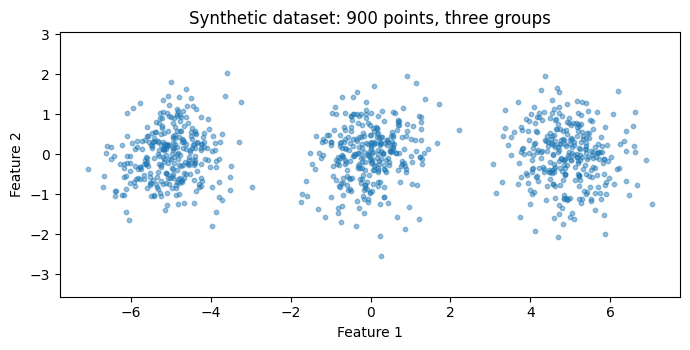

In [2]:
rng = np.random.default_rng(DATA_SEED)
generating_centres = np.array([[-5., 0.], [0., 0.], [5., 0.]])
X_synthetic = np.vstack([rng.normal(centre, 0.7, size=(300, 2)) for centre in generating_centres])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(X_synthetic[:, 0], X_synthetic[:, 1], s=10, alpha=0.45)
ax.set(title="Synthetic dataset: 900 points, three groups", xlabel="Feature 1", ylabel="Feature 2")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "synthetic_data.png", dpi=150)
plt.show()

## 3. MNIST dataset and preprocessing

[MNIST](https://keras.io/api/datasets/mnist/) contains handwritten digits from 0 to 9. Each image has 28 × 28 pixels. We download the archive and check its SHA-256 checksum against the [official Keras loader](https://github.com/keras-team/keras/blob/master/keras/src/datasets/mnist.py).

We select 2,000 of the 60,000 training images without repeats, using seed 42. Each image is converted into a row of 784 pixel values. Dividing by 255 puts the values between 0 and 1. This gives us a real dataset with many features, while keeping the repeated runs manageable. We choose k = 10 because the dataset contains ten digit categories.

MNIST sample: 2000 images × 784 pixel features


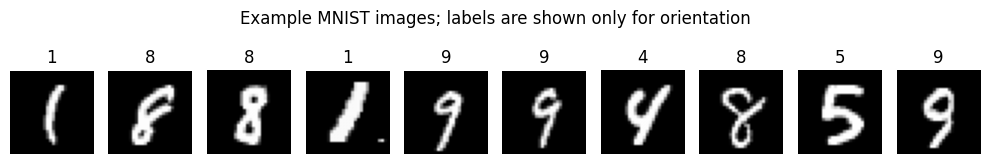

In [3]:
MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
MNIST_SHA256 = "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1"
mnist_path = DATA_DIR / "mnist.npz"
if not mnist_path.exists():
    urllib.request.urlretrieve(MNIST_URL, mnist_path)
assert hashlib.sha256(mnist_path.read_bytes()).hexdigest() == MNIST_SHA256, "MNIST checksum mismatch."
with np.load(mnist_path, allow_pickle=False) as archive:
    sample_ids = np.random.default_rng(DATA_SEED).choice(60000, MNIST_SAMPLE_SIZE, replace=False)
    images = archive["x_train"][sample_ids]
    digit_labels = archive["y_train"][sample_ids]
X_mnist = images.reshape(len(images), -1).astype(float) / 255.0
assert X_mnist.shape == (2000, 784) and len(np.unique(digit_labels)) == 10
print(f"MNIST sample: {X_mnist.shape[0]} images × {X_mnist.shape[1]} pixel features")
fig, axes = plt.subplots(1, 10, figsize=(10, 1.8))
for ax, image, label in zip(axes, images[:10], digit_labels[:10]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(str(label))
    ax.axis("off")
fig.suptitle("Example MNIST images; labels are shown only for orientation")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "mnist_examples.png", dpi=150)
plt.show()

### Evaluation protocol

The digit labels are shown with the example images, but the algorithm does not use them to form clusters. One cluster can contain different digits, and images of the same digit can end up in different clusters.

We use the same selected images in every run because we want to measure the effect of changing the starting centres. We therefore calculate inertia on these images without a separate training/test split.

### Extensions: overlapping groups and extra dimensions

For overlap, we keep the three generating centres, 900 points and k = 3. We change the coordinate standard deviation to 0.7, 1.5 and 2.5. Each setting uses the same underlying Gaussian random values, scaled to the chosen spread, where wider groups overlap more. The 0.7 setting is the original synthetic dataset.

For dimensionality, we keep the original two coordinates and add independent Gaussian noise features with mean zero and standard deviation 0.7. The total feature counts are 2, 10, 50, 200 and 784. These extra features are generated in the same way for all three groups, so they are not deliberately separating the groups further. Seed 43 fixes the noise matrix, and at each higher feature count, we keep the earlier columns and add more from that matrix.
We compare the methods within each setting, since changing the spread or number of coordinates also changes the scale of inertia.

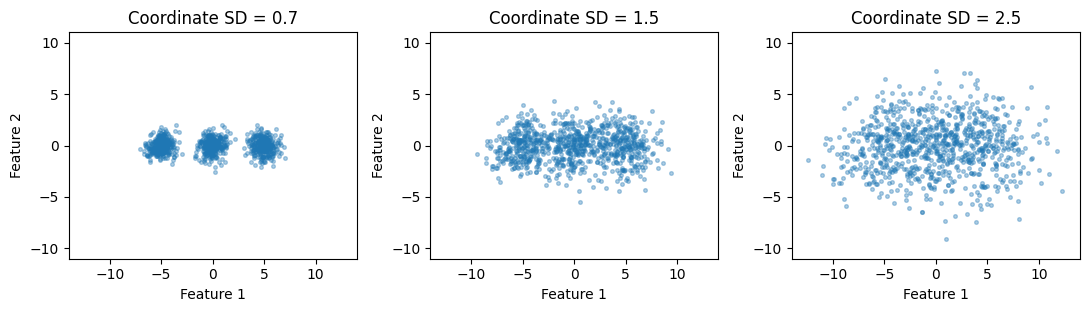

In [4]:
NOISE_SEED = 43
overlap_names = {0.7: "Synthetic", 1.5: "Overlap sigma=1.5", 2.5: "Overlap sigma=2.5"}
dimension_names = {2: "Synthetic", 10: "Noise d=10", 50: "Noise d=50", 200: "Noise d=200", 784: "Noise d=784"}
locations = np.repeat(generating_centres, 300, axis=0)
standard_offsets = np.random.default_rng(DATA_SEED).standard_normal(X_synthetic.shape)
assert np.allclose(X_synthetic, locations + 0.7 * standard_offsets)
overlap_data = {sigma: (X_synthetic if sigma == 0.7 else locations + sigma * standard_offsets)
                for sigma in overlap_names}
extra_features = np.random.default_rng(NOISE_SEED).normal(0, 0.7, size=(900, 782))
dimension_data = {d: (X_synthetic if d == 2 else np.column_stack((X_synthetic, extra_features[:, :d-2])))
                  for d in dimension_names}
extension_datasets = {overlap_names[sigma]: (X, 3) for sigma, X in overlap_data.items() if sigma != 0.7}
extension_datasets.update({dimension_names[d]: (X, 3) for d, X in dimension_data.items() if d != 2})
extension_conditions = {
    "overlap": [{"dataset": name, "sigma": sigma} for sigma, name in overlap_names.items()],
    "dimensionality": [{"dataset": name, "dimensions": d} for d, name in dimension_names.items()]
}
axis_limits = np.ceil(np.max(np.abs(np.vstack(list(overlap_data.values()))), axis=0)) + 1
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, (sigma, X) in zip(axes, overlap_data.items()):
    ax.scatter(X[:, 0], X[:, 1], s=7, alpha=0.35)
    ax.set(title=f"Coordinate SD = {sigma}", xlabel="Feature 1", ylabel="Feature 2",
           xlim=(-axis_limits[0], axis_limits[0]), ylim=(-axis_limits[1], axis_limits[1]))
    ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "overlap_data.png", dpi=170)
plt.show()


## 4. Implementation

Both methods try to reduce inertia: the sum of squared distances from each point to its nearest centre.

    J = sum over observations of the squared distance to the nearest centre

For the same data and k, lower inertia means tighter groups. We use NumPy to calculate distances, choose starting centres and update the groups.

In [5]:
def squared_distances(X, centres):
    """Return a matrix of squared distances: one row per point, one column per centre."""
    distances = (X ** 2).sum(axis=1)[:, None] + (centres ** 2).sum(axis=1)[None, :] - 2 * (X @ centres.T)
    return np.maximum(distances, 0.0)


def choose_initial_centres(X, k, method, rng):
    """Choose k data points by uniform random sampling or standard k-means++ seeding."""
    if method == "Random":
        return X[rng.choice(len(X), size=k, replace=False)].copy()
    if method != "k-means++":
        raise ValueError("Unknown initialization method.")
    chosen = [int(rng.integers(len(X)))]
    nearest_sq = squared_distances(X, X[chosen]).ravel()
    nearest_sq[chosen] = 0.0
    while len(chosen) < k:
        if nearest_sq.sum() > 0:
            index = int(rng.choice(len(X), p=nearest_sq / nearest_sq.sum()))
        else:
            remaining = np.setdiff1d(np.arange(len(X)), chosen)
            index = int(rng.choice(remaining))
        chosen.append(index)
        nearest_sq = np.minimum(nearest_sq, squared_distances(X, X[[index]]).ravel())
        nearest_sq[chosen] = 0.0
    return X[chosen].copy()

### Choosing the starting centres

Random initialization chooses k different observations, with every observation equally likely to be selected. K-means++ chooses its first centre in the same way. It then chooses each further centre using:

    D2(i) = squared distance from observation i to its nearest chosen centre
    p(i) = D2(i) / sum of D2 for all observations

Here p(i) is the probability of choosing observation i. D2 already contains a squared distance; it is not squared again. We update these distances after every new centre. Points farther from the existing centres have a greater chance of being selected.

An observation cannot be chosen twice. If all distances are zero, the code chooses another unused observation at random. The distance function calculates the same squared distance using:

    squared_distance(x, c) = sum(x * x) + sum(c * c) - 2 * dot(x, c)

The sums run over the features. The dot product multiplies the matching features of x and c and adds those products. Small negative values caused by rounding are clipped to zero.

In [6]:
def fit_kmeans(X, k, method="Random", seed=0, max_iter=200):
    """Lloyd's assign-and-average algorithm, with a selectable starting rule."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not np.isfinite(X).all() or not 1 <= k <= len(X):
        raise ValueError("Use a finite 2D array and 1 <= k <= number of rows.")
    centres = choose_initial_centres(X, k, method, np.random.default_rng(seed))
    initial_centres = centres.copy()
    distances = squared_distances(X, centres)
    labels = distances.argmin(axis=1)
    inertia_history = [float(distances.min(axis=1).sum())]
    converged = False

    for iteration in range(1, max_iter + 1):
        new_centres = centres.copy()
        farthest = distances.min(axis=1).copy()
        for cluster in range(k):
            members = X[labels == cluster]
            if len(members):
                new_centres[cluster] = members.mean(axis=0)
            else:
                index = int(farthest.argmax())
                new_centres[cluster] = X[index]
                farthest[index] = -np.inf
        distances = squared_distances(X, new_centres)
        new_labels = distances.argmin(axis=1)
        inertia_history.append(float(distances.min(axis=1).sum()))
        converged = np.array_equal(labels, new_labels)
        centres, labels = new_centres, new_labels
        if converged:
            break

    return {"centres": centres, "labels": labels, "initial_centres": initial_centres,
            "inertia": inertia_history[-1], "history": np.array(inertia_history),
            "iterations": iteration, "converged": converged}

### Updating the groups

Each observation is assigned to its nearest centre. The code then averages the observations in each group to find a new centre and assigns the observations again and both starting methods use this same loop.

A run stops when the assignments no longer change, or after 200 updates. If a cluster is empty, its centre is moved to an observation farthest from its assigned centre. The function returns the centres, assignments, inertia, update count and whether the run converged. We check that each run converged and that inertia didnt increase beyond rounding error.

## 5. Repeated runs and summary statistics

There are eight settings: the original synthetic data, MNIST, two extra overlap settings and four extra feature counts. Running both methods with 20 seeds gives 320 runs. The original two-dimensional results are reused in both extensions rather than calculated again.

For each setting, we report the mean final inertia, sample standard deviation, minimum and maximum. Standard deviation describes how much the scores vary between runs; its calculation uses denominator 20 − 1. Relative standard deviation is 100 × standard deviation / mean, which expresses this variation as a percentage.

We consider both the mean and the spread: getting the same score every time is useful only if the score is also good. Matching the seed numbers makes the experiment repeatable, but the two starting rules still choose different centres.

In [7]:
datasets = {"Synthetic": (X_synthetic, 3), "MNIST": (X_mnist, 10), **extension_datasets}
methods = ["Random", "k-means++"]
trial_rows, runs = [], {}
for dataset, (X, k) in datasets.items():
    for method in methods:
        for seed in TRIAL_SEEDS:
            model = fit_kmeans(X, k, method, seed, MAX_ITER)
            assert model["converged"], f"Unfinished run: {dataset}, {method}, {seed}"
            assert np.all(np.diff(model["history"]) <= 1e-7 * max(1.0, model["history"][0]))
            trial_rows.append({"dataset": dataset, "method": method, "seed": seed,
                               "initial_inertia": model["history"][0], "inertia": model["inertia"],
                               "iterations": model["iterations"], "converged": model["converged"]})
            runs[(dataset, method, seed)] = model
        print(f"Finished {dataset}: {method}, {len(TRIAL_SEEDS)} trials", flush=True)
trials = pd.DataFrame(trial_rows)
summary = trials.groupby(["dataset", "method"], sort=False)["inertia"].agg(
    trials="count", mean="mean", std="std", minimum="min", maximum="max"
).reset_index()
summary["relative_std_pct"] = 100 * summary["std"] / summary["mean"]
display(summary)


Finished Synthetic: Random, 20 trials


Finished Synthetic: k-means++, 20 trials


Finished MNIST: Random, 20 trials


Finished MNIST: k-means++, 20 trials


Finished Overlap sigma=1.5: Random, 20 trials


...

Finished Noise d=200: Random, 20 trials


Finished Noise d=200: k-means++, 20 trials


Finished Noise d=784: Random, 20 trials


Finished Noise d=784: k-means++, 20 trials


,dataset,method,trials,mean,std,minimum,maximum,relative_std_pct
0,Synthetic,Random,20,888.711,0.000,888.711,888.711,0.000
1,Synthetic,k-means++,20,888.711,0.000,888.711,888.711,0.000
2,MNIST,Random,20,78962.916,176.468,78737.683,79457.876,0.223
3,MNIST,k-means++,20,79049.737,211.037,78737.655,79497.417,0.267
4,Overlap sigma=1.5,Random,20,3730.362,0.229,3730.116,3730.564,0.006
5,Overlap sigma=1.5,k-means++,20,3730.373,0.243,3730.116,3730.776,0.007
6,Overlap sigma=2.5,Random,20,8665.846,1.362,8664.333,8668.143,0.016
7,Overlap sigma=2.5,k-means++,20,8666.099,1.517,8664.333,8668.143,0.018
8,Noise d=10,Random,20,4338.609,0.000,4338.609,4338.609,0.000
9,Noise d=10,k-means++,20,4338.609,0.000,4338.609,4338.609,0.000


## 6. Results and stability

Each dot represents one run. The box covers the middle half of the results, and the line inside it marks the median. The tables give the mean, standard deviation and full range. Each dataset has its own vertical scale because inertia depends on the data's size, number of features and scale.

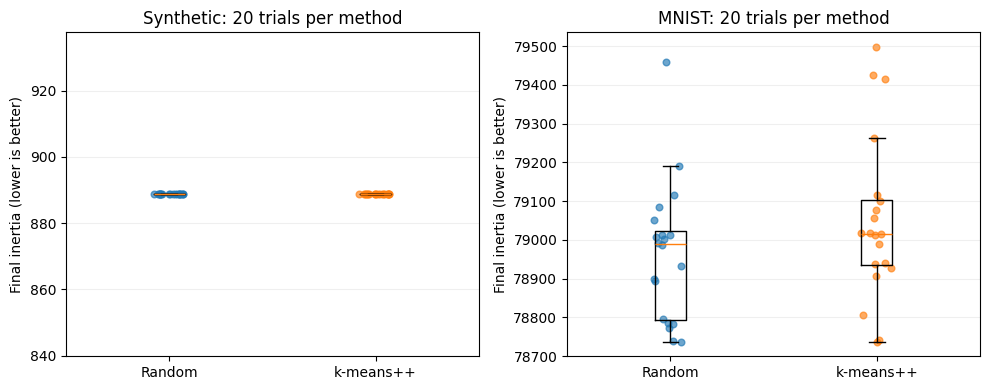

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
jitter_rng = np.random.default_rng(123)
for ax, dataset in zip(axes, ["Synthetic", "MNIST"]):
    values = [trials[(trials.dataset == dataset) & (trials.method == method)].inertia.to_numpy()
              for method in methods]
    ax.boxplot(values, tick_labels=methods, showfliers=False)
    for position, outcomes in enumerate(values, 1):
        ax.scatter(position + jitter_rng.uniform(-0.08, 0.08, len(outcomes)), outcomes, s=23, alpha=0.65)
    ax.set(title=f"{dataset}: 20 trials per method", ylabel="Final inertia (lower is better)")
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "inertia_distributions.png", dpi=160)
plt.show()

### 6.1 Synthetic results

| Initialization | Mean final inertia | Sample standard deviation | Minimum | Maximum |
|---|---:|---:|---:|---:|
| Random | 888.711 | 0.000 | 888.711 | 888.711 |
| k-means++ | 888.711 | 0.000 | 888.711 | 888.711 |

Both methods reached the same final inertia in every run, apart from rounding. All 40 runs converged.

### 6.2 MNIST results

| Initialization | Mean final inertia | Sample standard deviation | Minimum | Maximum |
|---|---:|---:|---:|---:|
| Random | 78,962.916 | 176.468 | 78,737.683 | 79,457.876 |
| k-means++ | 79,049.737 | 211.037 | 78,737.655 | 79,497.417 |

Random initialization gave lower average inertia by 86.821 (0.11%). Its standard deviation was also lower. All 40 runs converged.

The scores changed between runs even though the images, k and update rule stayed the same. This shows that choosing different starting centres can change the final result.

### 6.3 Extension results

The two-dimensional results are reused as the starting point for both extensions. Higher inertia after increasing the spread or adding features does not, on its own, show that initialization worked worse.

### 6.4 Overlapping groups

| Spread (sigma) | Random mean | k-means++ mean | Random SD | k-means++ SD | Random relative SD (%) | k-means++ relative SD (%) |
|---|---:|---:|---:|---:|---:|---:|
| 0.7 | 888.711 | 888.711 | 0.000 | 0.000 | 0.0000 | 0.0000 |
| 1.5 | 3,730.362 | 3,730.373 | 0.229 | 0.243 | 0.0061 | 0.0065 |
| 2.5 | 8,665.846 | 8,666.099 | 1.362 | 1.517 | 0.0157 | 0.0175 |

The methods had the same mean inertia with a spread of 0.7.

With a spread of 1.5, random initialization gave 0.0003% lower average inertia. With a spread of 2.5, random initialization gave 0.0029% lower average inertia.

Wider groups gave some variation in final inertia. The differences between the methods were small. Increasing the spread also increases the scale of inertia, so the comparisons above are made at each spread separately.

### 6.5 Extra noise features

| Features | Random mean | k-means++ mean | Random SD | k-means++ SD | Random relative SD (%) | k-means++ relative SD (%) |
|---|---:|---:|---:|---:|---:|---:|
| 2 | 888.711 | 888.711 | 0.000 | 0.000 | 0.0000 | 0.0000 |
| 10 | 4,338.609 | 4,338.609 | 0.000 | 0.000 | 0.0000 | 0.0000 |
| 50 | 21,990.794 | 21,990.794 | 0.000 | 0.000 | 0.0000 | 0.0000 |
| 200 | 88,184.207 | 88,184.207 | 0.000 | 0.000 | 0.0000 | 0.0000 |
| 784 | 345,294.461 | 344,944.397 | 1,294.718 | 804.252 | 0.3750 | 0.2332 |

The methods had the same mean inertia with 2, 10, 50 and 200 features.

With 784 features, k-means++ gave 0.1014% lower average inertia.

The added columns contain noise and leave all earlier coordinates unchanged. Adding columns increases the total inertia, so that increase alone does not mean the starting method performed worse. Relative SD shows the variation between runs as a percentage of the mean.

In [9]:
trials.to_csv(RESULTS_DIR / "trials.csv", index=False)
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)


## 7. Discussion

On the separated synthetic data, both methods reached the same final inertia in every run, apart from rounding.

On MNIST, random initialization gave lower average inertia by 86.821 (0.11%). Its standard deviation was also lower.

With 784 synthetic features, k-means++ gave lower average inertia by 350.064 (0.101%).

The starting rule mattered in some settings but made little or no difference in others. The tables and plots show both the average score and its variation, rather than relying on the best single run.

These results come from one generated dataset per setting, one MNIST sample, fixed values of k and 20 seeds per method. Other samples or cluster counts could give different results. Equal inertia also does not prove that every point has the same cluster assignment.